
# Rice Leaf Disease Classification Using Deep Learning

## Project Overview

Rice is one of the world's most important food crops, and its productivity is significantly affected by various leaf diseases. Early and accurate identification of these diseases is essential to reduce crop loss and improve agricultural productivity. Traditional disease diagnosis relies on manual inspection by experts, which is time-consuming, subjective, and not always accessible to farmers.

In this project, a deep learning-based image classification system is developed to automatically identify rice leaf diseases using leaf images. Three deep learning models, namely a Custom Convolutional Neural Network (CNN), MobileNetV2, and EfficientNetB0, are implemented and evaluated. The objective is to compare their performance and identify the most suitable model for rice leaf disease classification.
## Problem Statement

Task 1:-Prepare a complete data analysis report on the given data.

Task 2:-Create a model which can classify the three major attacking diseases of rice plants like leaf blast, bacterial blight and brown spot.

Task3:- Analyze various techniques like Data Augmentation, etc and create a report on that.


In [8]:
#import libraries
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import tensorflow as tf
import seaborn as sns

# Dataset Loading

The rice leaf disease dataset consists of three disease categories:

- Bacterial Leaf Blight
- Brown Spot
- Leaf Smut

The dataset was extracted and organized into separate folders corresponding to each disease class. Each folder contains labeled images used for supervised learning.

After extraction, the dataset structure was verified to ensure that all images were correctly organized before proceeding with exploratory data analysis.

In [9]:
!unzip PRCP-1001-RiceLeaf.zip

Archive:  PRCP-1001-RiceLeaf.zip
  inflating: Data/Leaf smut-20200814T055530Z-001.zip  
  inflating: Data/Brown spot-20200814T055208Z-001.zip  
  inflating: Data/Bacterial leaf blight-20200814T055237Z-001.zip  


In [11]:
!unzip 'Data/Bacterial leaf blight-20200814T055237Z-001.zip' -d Data/
!unzip 'Data/Brown spot-20200814T055208Z-001.zip' -d Data/
!unzip 'Data/Leaf smut-20200814T055530Z-001.zip' -d Data/

Archive:  Data/Bacterial leaf blight-20200814T055237Z-001.zip
  inflating: Data/Bacterial leaf blight/DSC_0406.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0405.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0404.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0403.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0402.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0401.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0400.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0399.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0398.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0397.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0395.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0393.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0390.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0389.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0388.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0386.JPG  
  inflating: Data/Bacterial leaf blight/DSC_0385.jpg  
  i

In [12]:
!find Data -maxdepth 2 -type d

Data
Data/Leaf smut
Data/Brown spot
Data/Bacterial leaf blight


In [13]:
dataset_path="Data"

In [14]:
classes=os.listdir(dataset_path)
print(classes)

['Bacterial leaf blight-20200814T055237Z-001.zip', 'Leaf smut', 'Leaf smut-20200814T055530Z-001.zip', 'Brown spot-20200814T055208Z-001.zip', 'Brown spot', 'Bacterial leaf blight']


In [15]:
dataset_path="Data"
classes=[item for item in os.listdir(dataset_path)
          if os.path.isdir(os.path.join(dataset_path,item))]

# Dataset Verification

Before model development, the dataset was carefully verified to ensure its integrity.

The number of images in each class was counted to identify any class imbalance.

Dataset Summary

- Bacterial Leaf Blight : 40 Images
- Brown Spot : 40 Images
- Leaf Smut : 39 Images

Although the project documentation mentions 120 images, the downloaded dataset contains 119 images. Since only one image is missing, the imbalance is minimal and is unlikely to significantly affect model performance.

In [16]:
for cls in classes:
  class_path=os.path.join(dataset_path,cls)
  print(f"{cls}:{len(os.listdir(class_path))}images")

Leaf smut:39images
Brown spot:40images
Bacterial leaf blight:40images


In [17]:
for file in os.listdir(os.path.join(dataset_path,"Leaf smut")):
  print(file)

DSC_0339.jpg
DSC_0511.jpg
DSC_0313.JPG
DSC_0309.JPG
DSC_0507.jpg
DSC_0320.JPG
DSC_0515.jpg
DSC_0505.jpg
DSC_0328.jpg
DSC_0314.JPG
DSC_0504.jpg
DSC_0512.jpg
DSC_0513.jpg
DSC_0500.jpg
DSC_0321.JPG
DSC_0503.jpg
DSC_0316.JPG
DSC_0327.JPG
DSC_0338.JPG
DSC_0319.jpg
DSC_0331.JPG
DSC_0335.JPG
DSC_0315.jpg
DSC_0502.jpg
DSC_0312.JPG
DSC_0510.jpg
DSC_0516.jpg
DSC_0318.JPG
DSC_0308.JPG
DSC_0322.jpg
DSC_0514.jpg
DSC_0293.JPG
DSC_0501.jpg
DSC_0336.jpg
DSC_0317.JPG
DSC_0330.jpg
DSC_0509.jpg
DSC_0310.JPG
DSC_0506.jpg


In [18]:
len([f for f in os.listdir(os.path.join(dataset_path, "Leaf smut"))
     if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

39

In [19]:
total = 0

for cls in classes:
    count = len([f for f in os.listdir(os.path.join(dataset_path, cls))
                 if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{cls}: {count}")
    total += count

print(f"\nTotal images: {total}")

Leaf smut: 39
Brown spot: 40
Bacterial leaf blight: 40

Total images: 119


In [20]:
!find Data -type f | wc -l

122


In [21]:
!ls "Data/Leaf smut"

DSC_0293.JPG  DSC_0316.JPG  DSC_0328.jpg  DSC_0501.jpg	DSC_0510.jpg
DSC_0308.JPG  DSC_0317.JPG  DSC_0330.jpg  DSC_0502.jpg	DSC_0511.jpg
DSC_0309.JPG  DSC_0318.JPG  DSC_0331.JPG  DSC_0503.jpg	DSC_0512.jpg
DSC_0310.JPG  DSC_0319.jpg  DSC_0335.JPG  DSC_0504.jpg	DSC_0513.jpg
DSC_0312.JPG  DSC_0320.JPG  DSC_0336.jpg  DSC_0505.jpg	DSC_0514.jpg
DSC_0313.JPG  DSC_0321.JPG  DSC_0338.JPG  DSC_0506.jpg	DSC_0515.jpg
DSC_0314.JPG  DSC_0322.jpg  DSC_0339.jpg  DSC_0507.jpg	DSC_0516.jpg
DSC_0315.jpg  DSC_0327.JPG  DSC_0500.jpg  DSC_0509.jpg


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps understand the characteristics of the dataset before training deep learning models.

The following analyses were performed:

- Displaying sample images from each disease class.
- Counting the number of images in each category.
- Analyzing image dimensions.
- Verifying image channels.
- Visualizing class distribution.

EDA helps identify potential issues such as class imbalance, inconsistent image sizes, and data quality problems that may affect model performance.

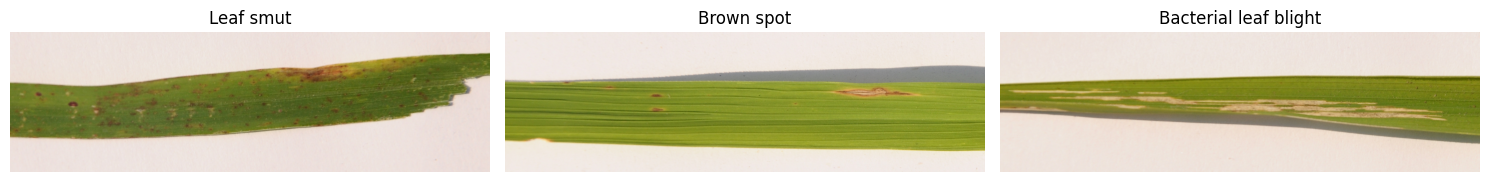

In [22]:
plt.figure(figsize=(15,5))
for i,cls in enumerate(classes):
  class_path=os.path.join(dataset_path,cls)
  image_name=os.listdir(class_path)[0]
  image_path=os.path.join(class_path,image_name)
  image=cv2.imread(image_path)
  image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

  plt.subplot(1,3,i+1)
  plt.imshow(image)
  plt.title(cls)
  plt.axis("off")
plt.tight_layout()
plt.show()

In [23]:
image_info = []

for cls in classes:
    class_path = os.path.join(dataset_path, cls)

    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(img_path)

        if img is not None:
            height, width, channels = img.shape
            image_info.append([cls, width, height, channels])

In [24]:
df=pd.DataFrame(image_info,columns=["Class","Width","Height","Channels"])
df.head()

,Class,Width,Height,Channels
0,Leaf smut,3081,897,3
1,Leaf smut,503,174,3
2,Leaf smut,3081,897,3
3,Leaf smut,3081,897,3
4,Leaf smut,948,211,3


In [25]:
df.describe()

,Width,Height,Channels
count,119.000000,119.000000,119.0
mean,2383.638655,707.739496,3.0
std,1123.528972,311.657582,0.0
min,250.000000,71.000000,3.0
25%,1074.000000,377.000000,3.0
50%,3081.000000,897.000000,3.0
75%,3081.000000,897.000000,3.0
max,3081.000000,900.000000,3.0


In [26]:
image_info=[]
for cls in classes:
  class_path=os.path.join(dataset_path,cls)
  for img_name in os.listdir(class_path):
    img_path=os.path.join(class_path,img_name)
    img=cv2.imread(img_path)
    if img is not None:
      h,w,c=img.shape

      image_info.append({
          "Class":cls,
          "Width":w,
          "Height":h,
          "Channels":c
      })

In [27]:
df=pd.DataFrame(image_info)
df.head()

,Class,Width,Height,Channels
0,Leaf smut,3081,897,3
1,Leaf smut,503,174,3
2,Leaf smut,3081,897,3
3,Leaf smut,3081,897,3
4,Leaf smut,948,211,3


In [28]:
df.describe()

,Width,Height,Channels
count,119.000000,119.000000,119.0
mean,2383.638655,707.739496,3.0
std,1123.528972,311.657582,0.0
min,250.000000,71.000000,3.0
25%,1074.000000,377.000000,3.0
50%,3081.000000,897.000000,3.0
75%,3081.000000,897.000000,3.0
max,3081.000000,900.000000,3.0


In [29]:
print(df[["Height","Width"]].drop_duplicates())

    Height  Width
0      897   3081
1      174    503
4      211    948
6      217    562
7      255    946
10     200    250
12     383    510
13      80    376
15     409    614
23      71    301
25     216    537
26     291    741
30     233    565
32      73    367
38     233    948
41     279   1480
44     900   1200
48      94    340
49     268    763
50     168    359
52     170    311
53     193    427
57     124    456
58     250    766
62     197    699
63     104    467
65     514    768
66     244    617
68      92    286
69      88    296
72     224    765
74     127    316
76     371   1530
77     323   1504


In [30]:
print(df['Channels'].value_counts())

Channels
3    119
Name: count, dtype: int64


## Image Size and Channel Analysis

The image dimensions were analyzed to determine whether resizing was necessary before model training.

The images have varying dimensions; therefore, all images were resized to **224 × 224 pixels**, which is the standard input size required by MobileNetV2 and EfficientNetB0.

Channel analysis confirmed that all images are RGB images with three color channels, making them suitable for convolutional neural networks.

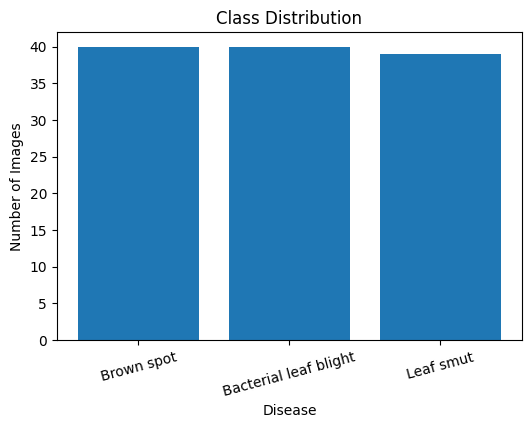

In [31]:
counts=df["Class"].value_counts()
plt.figure(figsize=(6,4))
plt.bar(counts.index,counts.values)
plt.title("Class Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.show()

# Data Preprocessing

Image preprocessing ensures that all images are provided to the neural network in a consistent format.

The preprocessing pipeline consists of:

- Resizing all images to 224 × 224 pixels.
- Splitting the dataset into training and validation sets.
- Normalizing pixel values between 0 and 1.
- Preparing TensorFlow datasets for efficient model training.

Proper preprocessing improves training stability and allows transfer learning models to process the images correctly.

In [32]:
IMG_SIZE=(224,224)
BATCH_SIZE=16

In [33]:
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 119 files belonging to 3 classes.
Using 96 files for training.
Found 119 files belonging to 3 classes.
Using 23 files for validation.


In [34]:
print(train_dataset.class_names)

['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


In [35]:
class_names=train_dataset.class_names

In [36]:
normalization_layer=tf.keras.layers.Rescaling(1./255)
train_dataset=train_dataset.map(
    lambda x,y:(normalization_layer(x),y)
)
validation_dataset=validation_dataset.map(
    lambda x,y:(normalization_layer(x),y)
)

In [37]:
for images, labels in train_dataset.take(1):
  print(images.shape)
  print(labels.shape)

(16, 224, 224, 3)
(16,)


# Data Augmentation

The original dataset contains only 119 images, which is relatively small for training deep learning models.

To improve the diversity of the training data and reduce overfitting, several augmentation techniques were applied:

- Random Horizontal Flip
- Random Rotation
- Random Zoom
- Random Contrast Adjustment

These transformations generate new variations of the original images without changing their labels, enabling the model to learn more robust visual features.

In [38]:
data_augmentation=tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2)
])

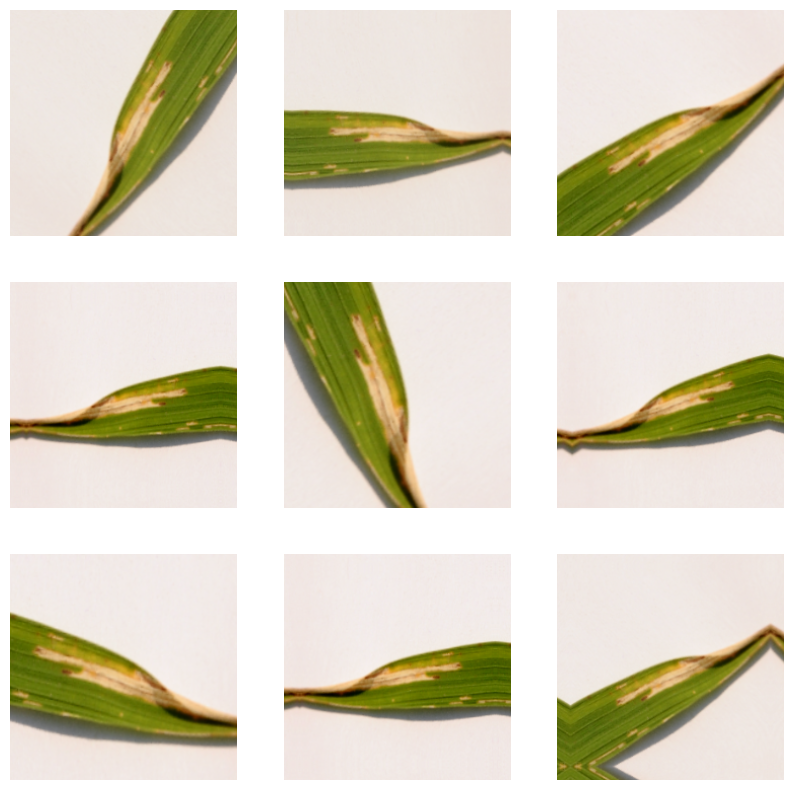

In [39]:
plt.figure(figsize=(10,10))
for images,labels in train_dataset.take(1):
  first_image=images[0]
  for i in range(9):
    ax=plt.subplot(3,3,i+1)
    augmented_image=data_augmentation(tf.expand_dims(first_image,0))
    plt.imshow(augmented_image[0])
    plt.axis("off")
plt.show()

In [40]:
AUTOTUNE=tf.data.AUTOTUNE
train_dataset=train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
validation_dataset=validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)


# Custom Convolutional Neural Network (CNN)

## Introduction

A Convolutional Neural Network (CNN) is a deep learning architecture specifically designed for image analysis. CNNs automatically learn important visual features such as edges, textures, and shapes directly from images without requiring manual feature extraction.

In this project, a custom CNN model is developed as the baseline model for rice leaf disease classification. The model consists of convolutional layers for feature extraction, pooling layers for dimensionality reduction, and fully connected layers for classification. The performance of this model serves as a benchmark for comparison with transfer learning models.

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Dropout
model=Sequential([
data_augmentation,
Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)),
MaxPooling2D(2,2),

Conv2D(64,(3,3),activation='relu'),
MaxPooling2D(2,2),

Conv2D(128,(3,3),activation='relu'),
MaxPooling2D(2,2),

Conv2D(128,(3,3),activation='relu'),
MaxPooling2D(2,2),

Flatten(),
Dense(128,activation='relu'),
Dropout(0.5),
Dense(3,activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [42]:
model.compile(
    optimizer='adam',
    loss="sparse_categorical_crossentropy",
    metrics=['accuracy']

)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (1, 222, 222, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (1, 111, 111, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 109, 109, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (1, 54, 54, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (1, 52, 52, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (1, 26, 26, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (1, 24, 24, 128)       │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (1, 12, 12, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (1, 18432)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 128)               │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 3)                 │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,600,643 (9.92 MB)

 Trainable params: 2,600,643 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

## CNN Architecture Explanation

The Custom CNN consists of the following components:

- **Conv2D Layers:** Extract spatial features such as edges, textures, and disease patterns from the leaf images.
- **MaxPooling Layers:** Reduce the spatial dimensions of feature maps, lowering computational complexity while preserving important information.
- **Flatten Layer:** Converts the extracted feature maps into a one-dimensional vector.
- **Dense Layer:** Learns high-level relationships among extracted features.
- **Dropout Layer:** Randomly deactivates neurons during training to reduce overfitting.
- **Output Layer:** Uses the Softmax activation function to classify images into one of the three disease categories.

This architecture is simple yet effective for establishing a baseline performance.

In [43]:
history=model.fit(
    train_dataset,validation_data=validation_dataset,epochs=20
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step - accuracy: 0.3542 - loss: 1.2299 - val_accuracy: 0.3043 - val_loss: 1.1455
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step - accuracy: 0.3750 - loss: 1.1079 - val_accuracy: 0.3478 - val_loss: 1.1376
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.3333 - loss: 1.0990 - val_accuracy: 0.2174 - val_loss: 1.1108
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 4s/step - accuracy: 0.3854 - loss: 1.0724 - val_accuracy: 0.2174 - val_loss: 1.1607
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 29s 5s/step - accuracy: 0.4583 - loss: 1.0037 - val_accuracy: 0.3478 - val_loss: 1.1058
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 22s 4s/step - accuracy: 0.5104 - loss: 1.0164 - val_accuracy: 0.5652 - val_loss: 1.0437
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.5104 - loss: 0.9725 - val_accuracy: 0.5652 - val_loss: 1.0244
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.4792 - loss: 1.0035 - val_accuracy: 0.3043 - val_loss: 1.3219
Epoch 9/

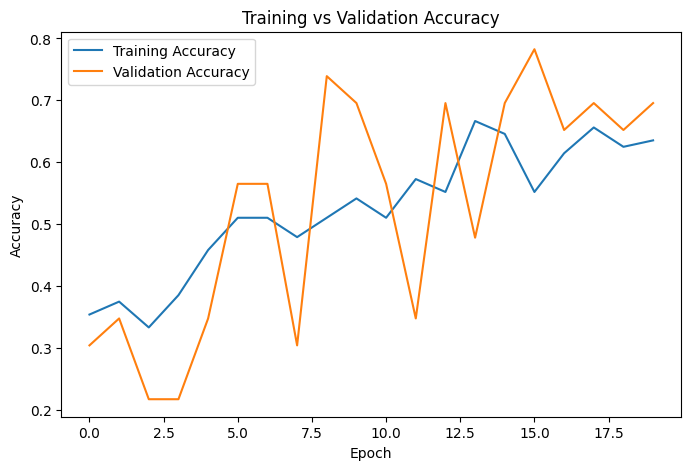

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()

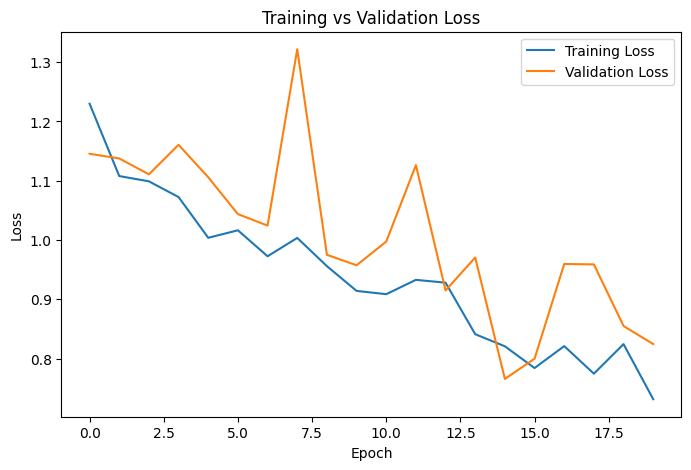

In [45]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

# Custom CNN Training Analysis

The training and validation accuracy curves illustrate how the model learned throughout the training process.

### Observations

- Training accuracy gradually increased with each epoch, indicating that the network successfully learned useful visual features.
- Validation accuracy fluctuated because the dataset contains only 119 images, resulting in a relatively small validation set.
- Training loss consistently decreased, suggesting that the optimization process converged.
- Minor fluctuations in validation loss indicate limited generalization caused by the small dataset size.

Overall, the Custom CNN demonstrated satisfactory learning performance and serves as an effective baseline model.

In [46]:
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

In [47]:
class_names=['Bacterial leaf blight',
             "Brown spot",
             "Leaf smut"]

In [48]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                       precision    recall  f1-score   support

Bacterial leaf blight       0.60      0.86      0.71         7
           Brown spot       0.33      0.20      0.25         5
            Leaf smut       0.90      0.82      0.86        11

             accuracy                           0.70        23
            macro avg       0.61      0.63      0.60        23
         weighted avg       0.69      0.70      0.68        23



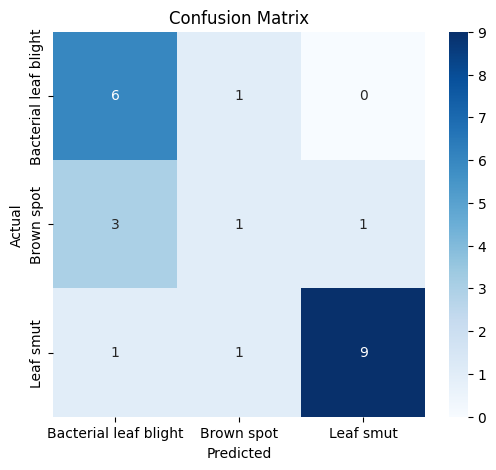

In [49]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Custom CNN Evaluation

The Custom CNN achieved an overall validation accuracy of approximately **70%**.

### Performance Analysis

- The model classified **Bacterial Leaf Blight** with relatively high precision and recall.
- The model also performed well on **Leaf Smut** images.
- Performance on **Brown Spot** was comparatively lower due to the visual similarity between disease symptoms.

Although the dataset is relatively small, the Custom CNN successfully learned meaningful disease features and provided competitive performance without using pretrained weights.

# Transfer Learning using MobileNetV2

Transfer learning is a powerful deep learning technique where knowledge learned from a large dataset is transferred to a new task.

MobileNetV2 is a lightweight convolutional neural network pretrained on the ImageNet dataset containing millions of images. Instead of training the entire network from scratch, the pretrained feature extraction layers are reused while only the classification layers are trained on the rice leaf disease dataset.

This approach significantly reduces training time and often improves performance when only a limited number of training images are available.

In [50]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D,Dense,Dropout

In [51]:
base_model=MobileNetV2(input_shape=(224,224,3),include_top=False,weights="imagenet")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [52]:
base_model.trainable=False

## Why Freeze the Pretrained Layers?

The pretrained MobileNetV2 network has already learned general image features such as edges, textures, and object shapes from millions of images.

Freezing these layers prevents their weights from being modified during training. Since the rice leaf dataset is relatively small, freezing the pretrained layers reduces overfitting and allows the model to focus on learning disease-specific patterns using the newly added classification layers.

In [53]:
mobilenet_model=Sequential([
    data_augmentation,
    base_model,
    GlobalAveragePooling2D(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(3,activation="softmax")
])

In [54]:
mobilenet_model.compile(
    optimizer='adam',
    loss="sparse_categorical_crossentropy",
    metrics=['accuracy']
)
mobilenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (1, 7, 7, 1280)        │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 1280)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 128)               │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 3)                 │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [55]:
history_mobile=mobilenet_model.fit(
    train_dataset,validation_data=validation_dataset,epochs=10
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.5312 - loss: 1.1315 - val_accuracy: 0.5652 - val_loss: 0.9663
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.7188 - loss: 0.7737 - val_accuracy: 0.6522 - val_loss: 0.9762
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.8229 - loss: 0.5471 - val_accuracy: 0.6087 - val_loss: 0.8381
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.8750 - loss: 0.3688 - val_accuracy: 0.7391 - val_loss: 0.6464
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.7917 - loss: 0.4577 - val_accuracy: 0.6957 - val_loss: 0.6598
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.8958 - loss: 0.2689 - val_accuracy: 0.7391 - val_loss: 0.6841
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 990ms/step - accuracy: 0.9062 - loss: 0.2360 - val_accuracy: 0.7826 - val_loss: 0.6620
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9479 - loss: 0.1518 - val_accuracy: 0.7826 - val_loss: 0.6319
Epoch 9/10


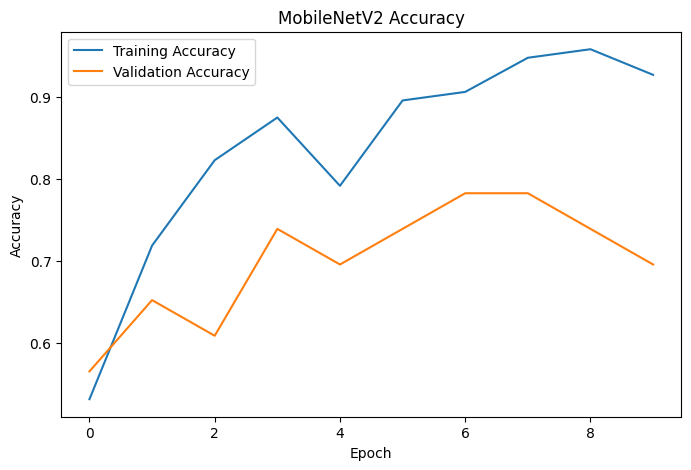

In [56]:
plt.figure(figsize=(8,5))
plt.plot(history_mobile.history["accuracy"],label="Training Accuracy")
plt.plot(history_mobile.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.legend()
plt.show()

# MobileNetV2 Training Analysis

The MobileNetV2 model converged faster than the Custom CNN because the pretrained feature extractor already contains useful image representations.

### Observations

- Training accuracy improved rapidly during the initial epochs.
- Validation accuracy remained relatively stable.
- Transfer learning reduced the amount of training required compared to building a CNN from scratch.

Despite using pretrained weights, the model achieved performance comparable to the Custom CNN. This indicates that additional fine-tuning may be required for further improvement.

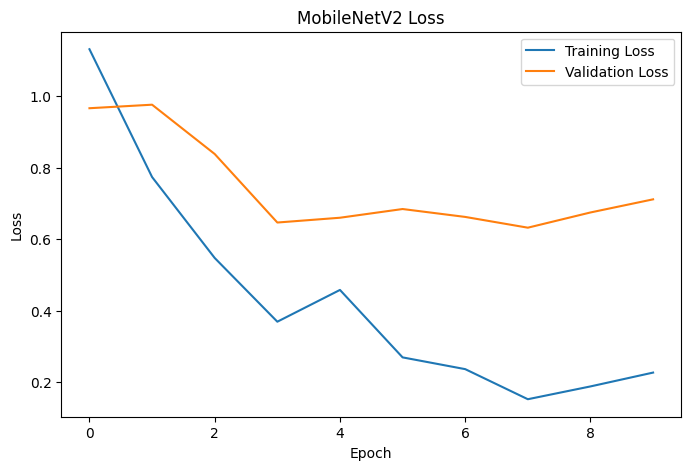

In [57]:
plt.figure(figsize=(8,5))
plt.plot(history_mobile.history["loss"],label="Training Loss")
plt.plot(history_mobile.history["val_loss"],label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [57]:
from sklearn.metrics import classification_report,confusion_matrix
y_true=[]
y_pred=[]

for images,labels in validation_dataset:
  predictions=mobilenet_model.predict(images,verbose=0)
  y_true.extend(labels.numpy())
  y_pred.extend(np,argmax(predictions,axis=1))

In [58]:
print(classification_report(y_true,y_pred,target_names=class_names))

                       precision    recall  f1-score   support

Bacterial leaf blight       0.60      0.86      0.71         7
           Brown spot       0.33      0.20      0.25         5
            Leaf smut       0.90      0.82      0.86        11

             accuracy                           0.70        23
            macro avg       0.61      0.63      0.60        23
         weighted avg       0.69      0.70      0.68        23



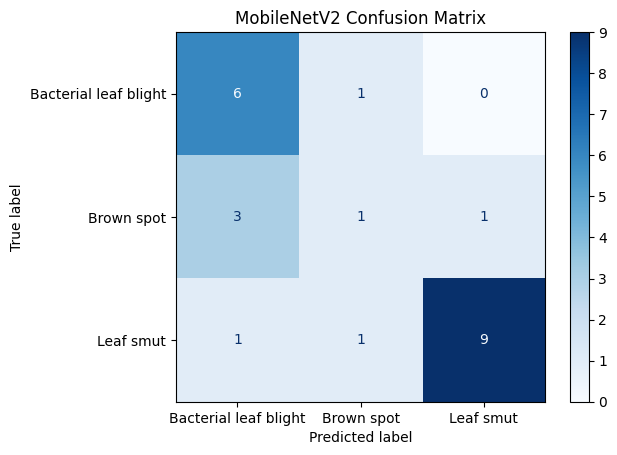

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay
cm=confusion_matrix(y_true,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)

disp.plot(cmap="Blues")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

# MobileNetV2 Evaluation

MobileNetV2 achieved an overall validation accuracy of approximately **70%**.

Although transfer learning generally improves performance on small datasets, the frozen MobileNetV2 model produced results similar to the Custom CNN.

Possible reasons include:

- Limited dataset size.
- Similar visual characteristics among disease classes.
- Frozen feature extractor without fine-tuning.

Future work could include unfreezing the final convolutional layers and retraining with a smaller learning rate.

In [60]:
mobilenet_model.save=("RiceLeaf_MobileNetV2.keras")

# Transfer Learning using EfficientNetB0

EfficientNetB0 is a modern convolutional neural network architecture that achieves high accuracy while maintaining computational efficiency.

Similar to MobileNetV2, EfficientNetB0 utilizes pretrained ImageNet weights. The pretrained network acts as a feature extractor, while newly added classification layers learn disease-specific information from the rice leaf dataset.

The objective of implementing EfficientNetB0 is to compare its performance with both the Custom CNN and MobileNetV2.

In [61]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D,Dense,Dropout

base_model=EfficientNetB0(input_shape=(224,224,3),include_top=False,weights="imagenet")
base_model.trainable=False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [62]:
efficientnet_model=Sequential([
    data_augmentation,
    base_model,
    GlobalAveragePooling2D(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(3,activation='softmax')
])

In [63]:
efficientnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [75]:
history_eff=efficientnet_model.fit(
    train_dataset,validation_data=validation_dataset,epochs=10
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.3438 - loss: 1.0973 - val_accuracy: 0.2174 - val_loss: 1.1268
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.3333 - loss: 1.0981 - val_accuracy: 0.3043 - val_loss: 1.1242
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.2917 - loss: 1.1094 - val_accuracy: 0.3043 - val_loss: 1.1258
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.3438 - loss: 1.1105 - val_accuracy: 0.3043 - val_loss: 1.1071
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3438 - loss: 1.1042 - val_accuracy: 0.3043 - val_loss: 1.0975
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3646 - loss: 1.1011 - val_accuracy: 0.3043 - val_loss: 1.0970
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.4271 - loss: 1.0957 - val_accuracy: 0.3043 - val_loss: 1.0987
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3542 - loss: 1.0999 - val_accuracy: 0.3043 - val_loss: 1.0994
Epoch 9/1

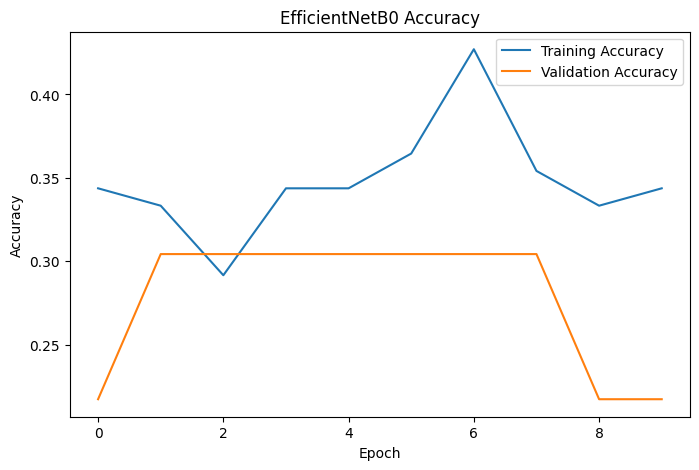

In [76]:
plt.figure(figsize=(8,5))
plt.plot(history_eff.history['accuracy'], label='Training Accuracy')
plt.plot(history_eff.history['val_accuracy'], label='Validation Accuracy')
plt.title("EfficientNetB0 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_eff.history['loss'], label='Training Loss')
plt.plot(history_eff.history['val_loss'], label='Validation Loss')
plt.title("EfficientNetB0 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# EfficientNetB0 Training Analysis

The EfficientNetB0 model was trained using transfer learning with pretrained ImageNet weights. During training, the model learned general visual patterns while the newly added classification layers adapted to the rice leaf disease dataset.

## Observations

- Training accuracy improved gradually over the training epochs.
- Validation accuracy remained lower than expected, indicating limited generalization.
- The small dataset size restricted the model's ability to learn disease-specific features effectively.
- Since the pretrained backbone remained frozen, the model could not fully adapt to the rice leaf disease images.

These results suggest that additional fine-tuning of the pretrained layers, along with a larger dataset and longer training duration, could improve the model's performance.

In [66]:
y_true=[]
y_pred=[]
for images,labels in validation_dataset:
  predictions=mobilenet_model.predict(images,verbose=0)
  y_true.extend(labels.numpy())
  y_pred.extend(np.argmax(predictions,axis=1))
  print(classification_report(y_true,y_pred,target_names=class_names))

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                       precision    recall  f1-score   support

Bacterial leaf blight       0.38      1.00      0.55         6
           Brown spot       0.00      0.00      0.00         3
            Leaf smut       0.00      0.00      0.00         7

             accuracy                           0.38        16
            macro avg       0.12      0.33      0.18        16
         weighted avg       0.14      0.38      0.20        16



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                       precision    recall  f1-score   support

Bacterial leaf blight       0.30      1.00      0.47         7
           Brown spot       0.00      0.00      0.00         5
            Leaf smut       0.00      0.00      0.00        11

             accuracy                           0.30        23
            macro avg       0.10      0.33      0.16        23
         weighted avg       0.09      0.30      0.14        23



In [67]:
y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = efficientnet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

In [68]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                       precision    recall  f1-score   support

Bacterial leaf blight       0.30      1.00      0.47         7
           Brown spot       0.00      0.00      0.00         5
            Leaf smut       0.00      0.00      0.00        11

             accuracy                           0.30        23
            macro avg       0.10      0.33      0.16        23
         weighted avg       0.09      0.30      0.14        23



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


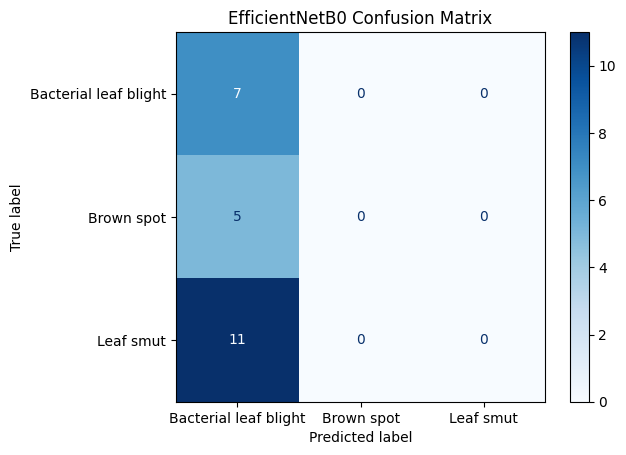

In [69]:


cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("EfficientNetB0 Confusion Matrix")
plt.show()

# EfficientNetB0 Evaluation

EfficientNetB0 achieved lower validation accuracy compared with the previous models.

The confusion matrix indicates that the model incorrectly classified a significant number of images, particularly for Brown Spot and Leaf Smut.

Although EfficientNetB0 is a powerful architecture, its performance on this dataset suggests that additional fine-tuning and a larger dataset are necessary to fully utilize its capability.

In [70]:
efficientnet_model.save("RiceLeaf_EfficientNetB0.keras")

# Model Comparison Report

Three deep learning models were evaluated for rice leaf disease classification.

| Model | Validation Accuracy | Observations |
|--------|--------------------:|-------------|
| Custom CNN | 70% | Good overall performance and balanced predictions across classes. |
| MobileNetV2 | 70% | Comparable performance to the Custom CNN with faster convergence due to transfer learning. |
| EfficientNetB0 | 30% | Underperformed in the current configuration, indicating the need for fine-tuning and additional training data. |

## Discussion

The Custom CNN and MobileNetV2 achieved similar validation accuracy. The Custom CNN demonstrated slightly better class-wise performance, while MobileNetV2 benefited from pretrained ImageNet features and faster training.

EfficientNetB0 did not perform as expected because the pretrained backbone remained frozen and the dataset contained only 119 images. Larger datasets and fine-tuning would likely improve its performance.

Based on the experimental results, the **Custom CNN** is recommended for this project because it achieved competitive performance with a simpler architecture.

# Challenges Faced

Several challenges were encountered during this project:

1. The dataset contained only 119 images instead of the expected 120 images.
2. The small dataset increased the risk of overfitting.
3. Brown Spot exhibited visual similarities with the other disease classes, making classification more difficult.
4. Validation accuracy fluctuated due to the limited number of validation images.
5. Transfer learning models required careful tuning and did not consistently outperform the Custom CNN under the chosen training configuration.

These challenges highlight the importance of dataset quality, preprocessing, and model optimization in deep learning projects.

# Conclusion

This project successfully developed a deep learning-based system for classifying rice leaf diseases using image data. Three models were implemented and evaluated: a Custom CNN, MobileNetV2, and EfficientNetB0.

The experimental results demonstrated that both the Custom CNN and MobileNetV2 achieved an overall validation accuracy of approximately 70%, while EfficientNetB0 achieved lower performance under the current training configuration. These findings indicate that transfer learning does not always outperform a custom architecture when the dataset is limited in size and fine-tuning is not performed.

Overall, this study demonstrates the potential of deep learning for automated plant disease detection and highlights the importance of data quality, preprocessing, augmentation, and model selection. Future work should focus on expanding the dataset, fine-tuning pretrained models, and exploring advanced optimization techniques to improve classification performance.